# XOR 과 역전파 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week09/xor_backprop/lab/xor_backprop.ipynb)

숨은 층의 가중치를 연쇄법칙으로 학습한다.

- **파트 1**: numpy 로 2-2-1 신경망 + 역전파 → XOR 100%
- **파트 2**: 기울기 확인 (역전파 vs 숫자로 조금 움직여 보기)
- **파트 3**: PyTorch `loss.backward()` 로 같은 계산 + 손글씨 숫자 분류

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 파트 1. 2-2-1 신경망과 역전파

$$\mathbf{h} = \sigma(\mathbf{x}W_1 + \mathbf{b}_1),\quad y = \sigma(\mathbf{h}\cdot\mathbf{w}_2 + b_2),\quad L = \tfrac12\sum (y - t)^2$$
$$\delta_2 = (y - t)\,y(1-y),\qquad \delta_1 = \delta_2\,\mathbf{w}_2 \odot \mathbf{h}(1-\mathbf{h}),\qquad \frac{\partial L}{\partial \mathbf{w}_2} = \mathbf{h}^\top\delta_2,\quad \frac{\partial L}{\partial W_1} = X^\top\delta_1$$

In [ ]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
t = np.array([0, 1, 1, 0], dtype=float)                   # XOR

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def forward(X, W1, b1, w2, b2):
    h = sigmoid(X @ W1 + b1)
    y = sigmoid(h @ w2 + b2)
    return h, y

def backward(X, t, h, y, w2):
    d2 = (y - t) * y * (1 - y)                            # output error signal
    d1 = None  # TODO: send d2 back through w2, times the sigmoid slope
    return {"w2": None, "b2": d2.sum(), "W1": None, "b1": d1.sum(axis=0)}  # TODO: gradients

def train(X, t, seed=3, lr=2.0, epochs=4000):
    r = np.random.default_rng(seed)
    W1, b1, w2, b2 = r.normal(0, 1, (2, 2)), np.zeros(2), r.normal(0, 1, 2), 0.0
    losses = []
    for _ in range(epochs + 1):
        h, y = forward(X, W1, b1, w2, b2)
        losses.append(0.5 * np.sum((y - t) ** 2))
        g = backward(X, t, h, y, w2)
        W1, b1, w2, b2 = W1 - lr * g["W1"], b1 - lr * g["b1"], w2 - lr * g["w2"], b2 - lr * g["b2"]
    return (W1, b1, w2, b2), losses

params, losses = train(X, t)
_, y = forward(X, *params)
print("outputs:", y.round(3), " accuracy:", ((y > 0.5) == t).mean())
plt.semilogy(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.show()

**예상 결과**

```
outputs: [0.012 0.986 0.986 0.013]  accuracy: 1.0
```

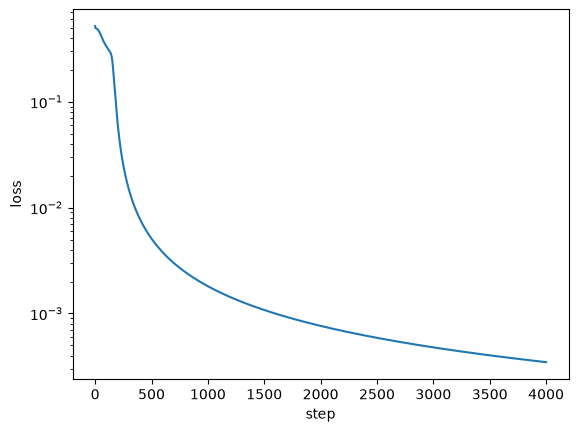

## 파트 2. 기울기 확인

역전파가 맞다면, 가중치 하나를 아주 조금 ($\epsilon$) 움직였을 때 손실이 변한 양 $\frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$ 과 같아야 한다.

In [ ]:
def loss(X, t, W1, b1, w2, b2):
    return 0.5 * np.sum((forward(X, W1, b1, w2, b2)[1] - t) ** 2)

r = np.random.default_rng(0)
W1, b1, w2, b2 = r.normal(0, 1, (2, 2)), r.normal(0, 1, 2), r.normal(0, 1, 2), 0.3
h, y = forward(X, W1, b1, w2, b2)
g = backward(X, t, h, y, w2)
eps = 1e-5
for (i, j) in [(0, 0), (1, 1)]:
    Wp, Wm = W1.copy(), W1.copy(); Wp[i, j] += eps; Wm[i, j] -= eps
    numeric = None  # TODO: central difference
    print(f"W1[{i},{j}]: backprop {g['W1'][i, j]:.6f}   numeric {numeric:.6f}")

**예상 결과**

```
W1[0,0]: backprop 0.027247   numeric 0.027247
W1[1,1]: backprop 0.021535   numeric 0.021535
```

## 파트 3. PyTorch 와 손글씨 숫자

같은 계산을 PyTorch 가 자동으로 한다 (`loss.backward()`). 그다음 실제 데이터: 8×8 손글씨 숫자 1,797장.

In [ ]:
import torch
Xt, tt = torch.tensor(X), torch.tensor(t)
W1_t = torch.tensor(W1, requires_grad=True); b1_t = torch.tensor(b1, requires_grad=True)
w2_t = torch.tensor(w2, requires_grad=True); b2_t = torch.tensor(b2, requires_grad=True)
y_t = torch.sigmoid(torch.sigmoid(Xt @ W1_t + b1_t) @ w2_t + b2_t)
L = 0.5 * ((y_t - tt) ** 2).sum()
L.backward()                                              # backpropagation, automatically
print("PyTorch dL/dW1:", W1_t.grad.numpy().round(6))
print("ours    dL/dW1:", g["W1"].round(6))

**예상 결과**

```
PyTorch dL/dW1: [[0.027247 0.01917 ]
 [0.029799 0.021535]]
ours    dL/dW1: [[0.027247 0.01917 ]
 [0.029799 0.021535]]
```

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
Xd, yd = load_digits(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xd / 16, yd, test_size=0.3, random_state=0, stratify=yd)
Xtr, Xte = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(Xte, dtype=torch.float32)
ytr, yte = torch.tensor(ytr), torch.tensor(yte)
torch.manual_seed(0)
net = torch.nn.Sequential(torch.nn.Linear(64, 32), torch.nn.Sigmoid(), torch.nn.Linear(32, 10))
opt = torch.optim.SGD(net.parameters(), lr=0.5)
for step in range(301):
    opt.zero_grad()
    loss_d = torch.nn.functional.cross_entropy(net(Xtr), ytr)
    pass  # TODO: compute the gradients
    opt.step()
    if step % 100 == 0:
        acc = (net(Xte).argmax(1) == yte).float().mean().item()
        print(f"step {step}: loss {loss_d.item():.3f}  test accuracy {acc:.3f}")

**예상 결과**

```
step 0: loss 2.312  test accuracy 0.102
step 100: loss 1.283  test accuracy 0.835
step 200: loss 0.533  test accuracy 0.907
step 300: loss 0.328  test accuracy 0.939
```

**확인 질문**
1. 파트 1 에서 숨은 뉴런을 2개에서 1개로 줄이면 (`(2, 1)`) XOR 을 풀 수 있나? 왜?
2. 파트 1 에서 시드를 바꾸면 가끔 75% 에 멈춘다. 왜 그럴까? (힌트: 지역 최솟값)
3. 파트 2 에서 두 기울기가 소수 몇째 자리까지 같은가?
4. 파트 3 의 손글씨 신경망에서 숨은 층을 없애면 (`Linear(64, 10)` 하나) 정확도는 어떻게 되나?

데이터 출처: Alpaydin & Kaynak, Optical Recognition of Handwritten Digits, UCI (scikit-learn `load_digits`).